<img src="images/image4.png" width=600>

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [34]:
a=np.array([
    [1,5,10,100],
    [2,13,20,100],
    [3,7,30,100],
    [4,8,40,100]
])

print(a[:,0].shape)


(4,)


(2,)


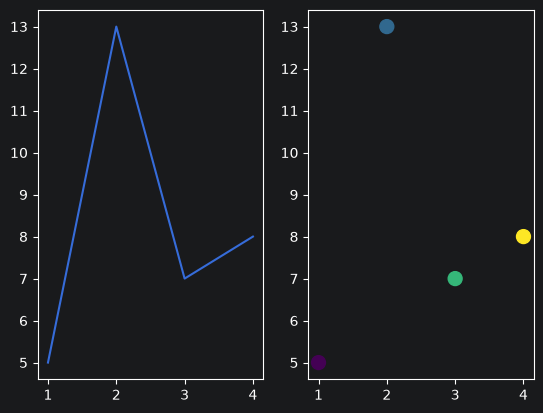

In [36]:
fig,ax = plt.subplots(1,2)
print(ax.shape)

x = a[:,0]
y = a[:,1]
colors = a[:,2]
sizes = a[:,3]

ax[0].plot(x,y)
ax[1].scatter(x,y,s=sizes, c=colors)
plt.show()


## No — The Indexing Is Wrong for a 1×2 Grid

The bug: `plt.subplots(1, 2)` creates a **1-dimensional** array of axes (since it's a single row), so you index it with **one** number (`ax[0]`), not two (`ax[0, 0]`). Let me show you.

---

### What `plt.subplots(1, 2)` Returns — A 1D Array

```python
fig, ax = plt.subplots(1, 2)
print(ax.shape)      # → (2,)   ← ONE dimension, 2 elements
```

Because it's **1 row × 2 columns**, matplotlib gives you a **flat 1D array** of 2 axes — shape `(2,)`, not `(1, 2)`. So you access them with a **single** index:

```python
ax[0]      # first subplot  ✓
ax[1]       # second subplot ✓
ax[0, 0]     # ✗ IndexError — too many indices for a 1D array!
```

Your `ax[0, 0]` uses **two** indices on a **1D** array, which fails.

---

### The Fix

```python
ax[0].plot(a[:, 0])      # ← single index, not ax[0,0]
```

---

### VerifyingConfirmed — `subplots(1, 2)` gives a `(2,)` 1D array (use `ax[0]`), while `ax[0, 0]` raises `IndexError`.

---

### The Rule — Indexing Depends on the Grid Shape

The shape of `ax` (and how you index it) changes based on the grid:

| `plt.subplots(...)` | `ax.shape` | How to index |
|---|---|---|
| `subplots()` or `subplots(1, 1)` | **not an array** — single axes | `ax.plot(...)` (no index) |
| `subplots(1, 2)` — one row | `(2,)` 1D | `ax[0]`, `ax[1]` |
| `subplots(3, 1)` — one column | `(3,)` 1D | `ax[0]`, `ax[1]`, `ax[2]` |
| `subplots(2, 3)` — grid | `(2, 3)` 2D | `ax[row, col]` — e.g. `ax[0, 2]` |

**Key insight (connects to your 1D-vs-2D lessons!):** a single row *or* single column gives a **flat 1D array** (one index), while a genuine grid (multiple rows AND columns) gives a **2D array** (two indices). This is exactly the "shape determines indexing" idea from NumPy — `(2,)` needs one index, `(2,3)` needs two.

---

### The Corrected Code

```python
import matplotlib.pyplot as plt
import numpy as np

a = np.array([
    [1, 5],
    [2, 6],
    [3, 7],
    [4, 8]
])

fig, ax = plt.subplots(1, 2)
print(ax.shape)              # → (2,)

ax[0].plot(a[:, 0])          # first subplot: plots column 0 → [1,2,3,4]
ax[1].plot(a[:, 1])          # second subplot: plots column 1 → [5,6,7,8]

plt.show()
```

I also added `ax[1].plot(...)` so your second subplot gets used — otherwise it'd be empty. `a[:, 0]` is column 0 (`[1,2,3,4]`), `a[:, 1]` is column 1 (`[5,6,7,8]`).

---

### Why `print(ax.shape)` Is Actually a Smart Debugging Move

You included `print(ax.shape)` — that's exactly the right instinct! It tells you immediately whether `ax` is 1D or 2D, so you know how to index it. Seeing `(2,)` tells you "use one index," while `(2, 3)` would tell you "use two." Checking the shape before indexing avoids this exact error.

---

### The One-Sentence Summary

> No — `plt.subplots(1, 2)` returns a **1D** array of axes (shape `(2,)`, since it's a single row), so you index it with **one** number: `ax[0]` and `ax[1]`, not `ax[0, 0]` (which raises `IndexError` for using two indices on a 1D array). Only a genuine grid with multiple rows *and* columns (like `subplots(2, 3)`) gives a **2D** array that you index as `ax[row, col]` — the same "shape determines how many indices" rule from your NumPy lessons. 🎯

## Using Array Columns for Color and Size — Vectorized Styling

If your size and color values live in **columns of your array**, you just pass those columns to the `s=` (size) and `c=` (color) parameters of `scatter`. Each point gets styled by its own row's values — no loop needed. Let me show you.

---

### Setup — Your Data Layout

Suppose your array has: x in column 0, y in column 1, **size in column 2**, **color-value in column 3**:

```python
import numpy as np

a = np.array([
    [1, 5, 100, 10],      # x=1, y=5, size=100, color-value=10
    [2, 6, 200, 20],
    [3, 7, 300, 30],
    [4, 8, 400, 40],
])
#    │  │   │    │
#   x  y  size  color
#  col0 col1 col2 col3
```

---

### Extract Each Column and Pass It In

```python
import matplotlib.pyplot as plt

x     = a[:, 0]      # column 0 → x positions
y     = a[:, 1]       # column 1 → y positions
sizes = a[:, 2]        # column 2 → sizes
colors = a[:, 3]        # column 3 → color values

plt.scatter(x, y, s=sizes, c=colors, cmap="viridis")
plt.colorbar()          # shows the color → value scale
plt.show()
```

**`s=sizes`** and **`c=colors`** accept **whole arrays** — one value per point. `scatter` is vectorized: each point `i` automatically uses `sizes[i]` and `colors[i]`. This is the same vectorization idea you learned — no loop, the whole column is applied at once.

---

### VerifyingEach point now gets its size from column 2 and its color from column 3 — all applied at once from the array columns.

---

### How Each Parameter Reads Its Column

```
a = [[1, 5, 100, 10],        point 0: at (1,5), size 100, color-value 10
     [2, 6, 200, 20],         point 1: at (2,6), size 200, color-value 20
     [3, 7, 300, 30],         ...
     [4, 8, 400, 40]]

plt.scatter(a[:,0], a[:,1], s=a[:,2], c=a[:,3], cmap="viridis")
            └──x──┘ └──y──┘   └─size─┘ └─color─┘
```

`scatter` pairs them up by position: point 0 uses `x[0], y[0], sizes[0], colors[0]`, and so on — the same "lockstep pairing" idea from fancy indexing.

---

### One-Liner Version (no intermediate variables)

```python
plt.scatter(a[:, 0], a[:, 1], s=a[:, 2], c=a[:, 3], cmap="viridis")
plt.colorbar()
```

Passing the column slices directly — cleaner if you don't need the named variables.

---

### Key Details

**`s=` (size)** — the numbers are point areas in points². Larger value → bigger point. Your column values (100, 200...) work directly.

**`c=` (color) with `cmap=`** — when `c` is an array of **numbers**, you add `cmap=` (a colormap like `"viridis"`, `"plasma"`, `"coolwarm"`) to map those numbers to colors. Low values → one end of the color scale, high → the other. `plt.colorbar()` shows the mapping.

**If column 3 were actual color names** (strings like `"red"`, `"blue"`) instead of numbers, you'd skip `cmap`:
```python
plt.scatter(x, y, s=sizes, c=["red", "green", "blue", "orange"])
```

---

### Why This Is Powerful — Visualizing 4 Dimensions at Once

This lets a single scatter plot show **four variables** simultaneously:
- **x position** (column 0)
- **y position** (column 1)
- **point size** (column 2)
- **point color** (column 3)

Very common in data analysis/ML — e.g., plotting data where position shows two features, size shows a third (like population), and color shows a fourth (like a category or score).

---

### The One-Sentence Summary

> Pass the array columns directly to `scatter`'s styling parameters: **`s=a[:, 2]`** for size and **`c=a[:, 3]`** for color (add `cmap="viridis"` when the color column holds numbers, so they map to a color scale). `scatter` is vectorized — it applies each point's own row values automatically, no loop needed — letting one plot encode four variables at once (x, y, size, color), which is a standard data-visualization technique. 🎯